In [1]:

# Install required libraries in Google Colab

!pip install -q pandas numpy matplotlib seaborn plotly scikit-learn


In [2]:

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import plotly.graph_objects as go

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from IPython.display import display

import warnings
warnings.filterwarnings("ignore")

# Visualization settings
sns.set_theme(style="whitegrid")

pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


In [3]:

# Generate an educational synthetic car dataset

np.random.seed(42)

n = 2500

brands = [
    "Toyota", "Honda", "BMW", "Mercedes",
    "Hyundai", "Maruti", "Audi", "Kia"
]

fuel_types = ["Petrol", "Diesel", "Hybrid", "Electric"]
transmissions = ["Manual", "Automatic"]

brand = np.random.choice(brands, n)

year = np.random.randint(2010, 2027, n)

mileage = np.random.randint(1000, 180001, n)

engine_size = np.round(
    np.random.uniform(0.8, 5.0, n), 1
)

horsepower = np.round(
    engine_size * np.random.uniform(25, 65, n)
    + np.random.normal(0, 25, n)
).astype(int)

horsepower = np.maximum(horsepower, 40)

fuel_type = np.random.choice(
    fuel_types,
    n,
    p=[0.48, 0.27, 0.15, 0.10]
)

transmission = np.random.choice(
    transmissions,
    n,
    p=[0.4, 0.6]
)

doors = np.random.choice(
    [2, 4, 5],
    n,
    p=[0.08, 0.55, 0.37]
)

# Brand price multipliers
brand_multiplier = {
    "Toyota": 1.15,
    "Honda": 1.10,
    "BMW": 1.75,
    "Mercedes": 1.90,
    "Hyundai": 0.95,
    "Maruti": 0.75,
    "Audi": 1.70,
    "Kia": 1.00
}

brand_factor = np.array([
    brand_multiplier[b] for b in brand
])

# Fuel price multipliers
fuel_multiplier = {
    "Petrol": 1.00,
    "Diesel": 1.08,
    "Hybrid": 1.25,
    "Electric": 1.40
}

fuel_factor = np.array([
    fuel_multiplier[f] for f in fuel_type
])

# Transmission multiplier
transmission_factor = np.where(
    transmission == "Automatic",
    1.12,
    1.00
)

# Age of vehicle
age = 2026 - year

# Simulated price formula
base_price = (
    350000
    + horsepower * 8500
    + engine_size * 180000
)

age_factor = np.exp(-0.075 * age)

mileage_factor = np.exp(-mileage / 220000)

# Add realistic variation and noise
noise = np.random.normal(1.0, 0.12, n)

price = (
    base_price
    * brand_factor
    * fuel_factor
    * transmission_factor
    * age_factor
    * mileage_factor
    * noise
)

price = np.maximum(price, 80000)

# Create DataFrame
df = pd.DataFrame({
    "Brand": brand,
    "Year": year,
    "Mileage": mileage,
    "Engine_Size": engine_size,
    "Horsepower": horsepower,
    "Fuel_Type": fuel_type,
    "Transmission": transmission,
    "Doors": doors,
    "Price": price.astype(int)
})

print("Dataset generated successfully!")

display(df.head(10))

print("\nDataset shape:", df.shape)
print("\nDataset columns:")
print(df.columns.tolist())


Dataset generated successfully!


,Brand,Year,Mileage,Engine_Size,Horsepower,Fuel_Type,Transmission,Doors,Price
0,Audi,2023,70504,4.5,150,Petrol,Automatic,5,2895911
1,Mercedes,2024,100214,2.6,114,Hybrid,Manual,2,2565434
2,Hyundai,2023,114936,2.7,121,Diesel,Automatic,4,970426
3,Audi,2016,17279,2.1,74,Hybrid,Manual,4,1235565
4,BMW,2026,104751,3.8,245,Hybrid,Automatic,4,3725504
5,Kia,2021,105433,2.3,131,Diesel,Automatic,5,953843
6,Hyundai,2013,72386,1.9,66,Diesel,Automatic,5,319276
7,Hyundai,2018,87124,2.6,71,Petrol,Automatic,4,512377
8,Audi,2015,106750,1.2,61,Hybrid,Manual,4,591667
9,Honda,2025,78485,3.9,176,Petrol,Manual,4,1567613



Dataset shape: (2500, 9)

Dataset columns:
['Brand', 'Year', 'Mileage', 'Engine_Size', 'Horsepower', 'Fuel_Type', 'Transmission', 'Doors', 'Price']


In [4]:

# Dataset information

print("DATASET INFORMATION")
print("=" * 50)

print("\nNumber of rows:", len(df))
print("Number of columns:", len(df.columns))

print("\nData types:")
display(df.dtypes)

print("\nMissing values:")
display(df.isnull().sum())

print("\nStatistical summary:")
display(df.describe())

print("\nCategorical information:")
display(df.describe(include="object"))


DATASET INFORMATION

Number of rows: 2500
Number of columns: 9

Data types:


,0
Brand,object
Year,int64
Mileage,int64
Engine_Size,float64
Horsepower,int64
Fuel_Type,object
Transmission,object
Doors,int64
Price,int64



Missing values:


,0
Brand,0
Year,0
Mileage,0
Engine_Size,0
Horsepower,0
Fuel_Type,0
Transmission,0
Doors,0
Price,0



Statistical summary:


,Year,Mileage,Engine_Size,Horsepower,Doors,Price
count,2500.000000,2500.000000,2500.000000,2500.000000,2500.000000,2.500000e+03
mean,2018.075200,90126.953600,2.913920,132.916800,4.217200,1.207719e+06
std,4.921385,51610.129734,1.213585,69.018514,0.803419,8.655165e+05
min,2010.000000,1060.000000,0.800000,40.000000,2.000000,9.915300e+04
25%,2014.000000,44912.750000,1.900000,75.000000,4.000000,6.007862e+05
50%,2018.000000,90277.000000,2.900000,124.000000,4.000000,9.678695e+05
75%,2022.000000,135746.750000,3.900000,180.000000,5.000000,1.561501e+06
max,2026.000000,179986.000000,5.000000,359.000000,5.000000,6.757651e+06



Categorical information:


,Brand,Fuel_Type,Transmission
count,2500,2500,2500
unique,8,4,2
top,Toyota,Petrol,Automatic
freq,329,1204,1470


In [5]:

# Clean the dataset

df = df.drop_duplicates()

# Remove invalid records
df = df[
    (df["Price"] > 0) &
    (df["Mileage"] >= 0) &
    (df["Horsepower"] > 0) &
    (df["Engine_Size"] > 0)
].copy()

# Handle missing values
df = df.dropna()

print("Data cleaning completed!")

print("Rows after cleaning:", len(df))
print("Missing values remaining:", df.isnull().sum().sum())

display(df.head())


Data cleaning completed!
Rows after cleaning: 2500
Missing values remaining: 0


,Brand,Year,Mileage,Engine_Size,Horsepower,Fuel_Type,Transmission,Doors,Price
0,Audi,2023,70504,4.5,150,Petrol,Automatic,5,2895911
1,Mercedes,2024,100214,2.6,114,Hybrid,Manual,2,2565434
2,Hyundai,2023,114936,2.7,121,Diesel,Automatic,4,970426
3,Audi,2016,17279,2.1,74,Hybrid,Manual,4,1235565
4,BMW,2026,104751,3.8,245,Hybrid,Automatic,4,3725504


In [6]:

# Calculate dashboard statistics

total_cars = len(df)

average_price = df["Price"].mean()

median_price = df["Price"].median()

minimum_price = df["Price"].min()

maximum_price = df["Price"].max()

average_mileage = df["Mileage"].mean()

print("=" * 55)
print("             CAR ANALYTICS DASHBOARD")
print("=" * 55)

print(f"Total Cars:       {total_cars:,}")
print(f"Average Price:    ₹{average_price:,.0f}")
print(f"Median Price:     ₹{median_price:,.0f}")
print(f"Minimum Price:    ₹{minimum_price:,.0f}")
print(f"Maximum Price:    ₹{maximum_price:,.0f}")
print(f"Average Mileage:  {average_mileage:,.0f} km")
print("=" * 55)


             CAR ANALYTICS DASHBOARD
Total Cars:       2,500
Average Price:    ₹1,207,719
Median Price:     ₹967,870
Minimum Price:    ₹99,153
Maximum Price:    ₹6,757,651
Average Mileage:  90,127 km


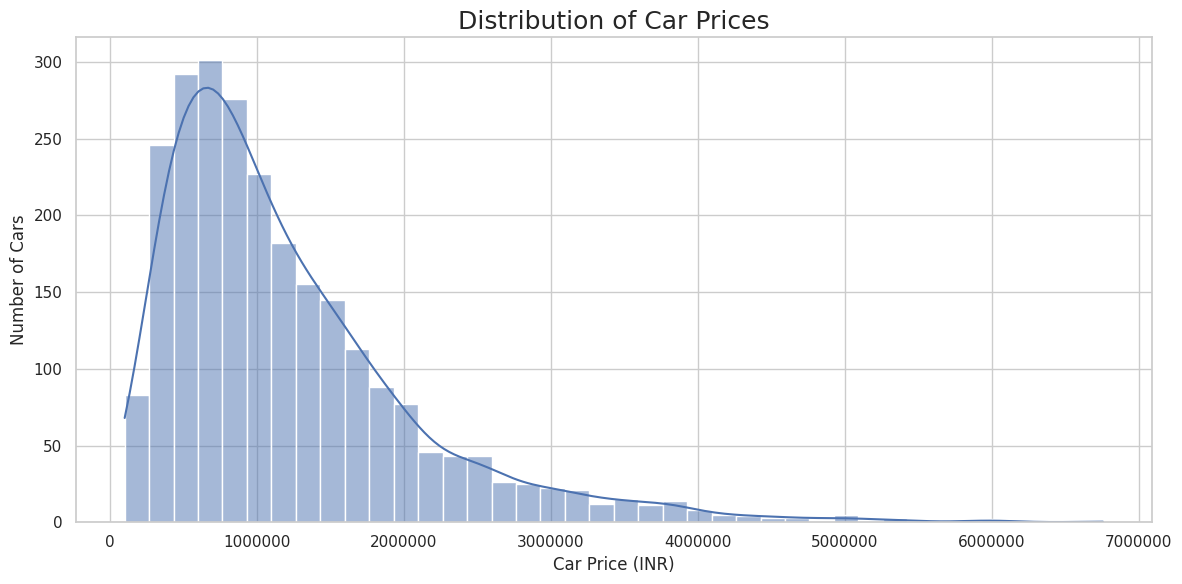

In [7]:

# Car price distribution

plt.figure(figsize=(12, 6))

sns.histplot(
    data=df,
    x="Price",
    bins=40,
    kde=True
)

plt.title(
    "Distribution of Car Prices",
    fontsize=18
)

plt.xlabel("Car Price (INR)")
plt.ylabel("Number of Cars")

plt.ticklabel_format(
    style="plain",
    axis="x"
)

plt.tight_layout()
plt.show()


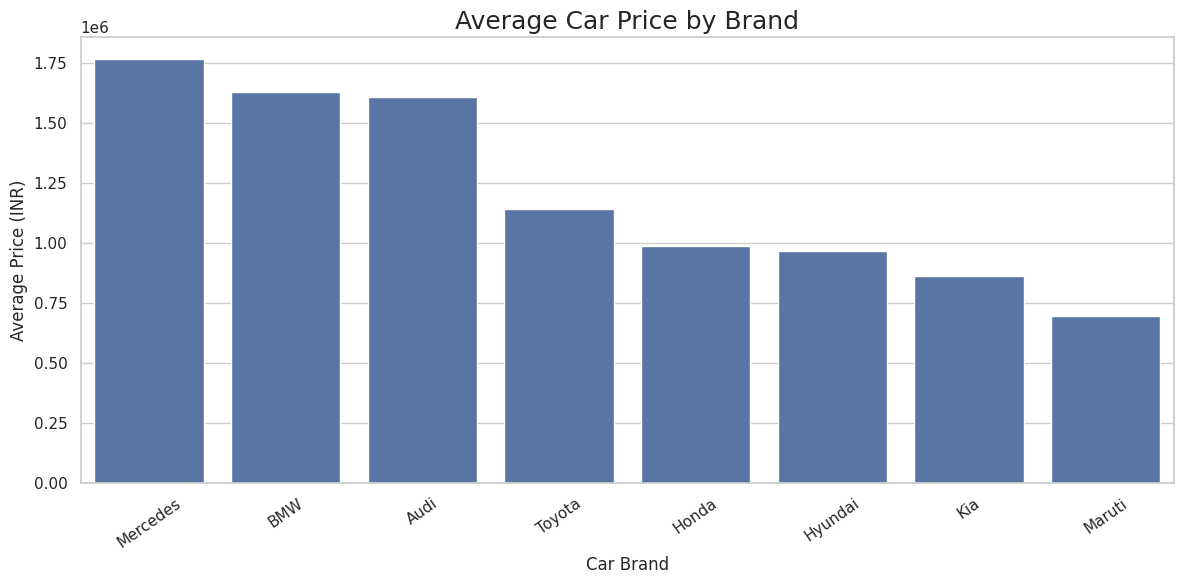

,Brand,Price
0,Mercedes,1.770037e+06
1,BMW,1.628480e+06
2,Audi,1.610544e+06
3,Toyota,1.143639e+06
4,Honda,9.888079e+05
5,Hyundai,9.657991e+05
6,Kia,8.626253e+05
7,Maruti,6.964069e+05


In [8]:

# Average price by brand

brand_prices = (
    df.groupby("Brand")["Price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

plt.figure(figsize=(12, 6))

sns.barplot(
    data=brand_prices,
    x="Brand",
    y="Price"
)

plt.title(
    "Average Car Price by Brand",
    fontsize=18
)

plt.xlabel("Car Brand")
plt.ylabel("Average Price (INR)")

plt.xticks(rotation=35)

plt.tight_layout()
plt.show()

display(brand_prices)


In [9]:

# Average price by fuel type

fuel_prices = (
    df.groupby("Fuel_Type")["Price"]
    .mean()
    .sort_values(ascending=False)
    .reset_index()
)

fig = px.bar(
    fuel_prices,
    x="Fuel_Type",
    y="Price",
    color="Fuel_Type",
    title="Average Car Price by Fuel Type",
    labels={
        "Price": "Average Price (INR)",
        "Fuel_Type": "Fuel Type"
    },
    text_auto=".2s"
)

fig.update_layout(
    template="plotly_white",
    height=500
)

fig.show()

display(fuel_prices)


,Fuel_Type,Price
0,Electric,1.522388e+06
1,Hybrid,1.364163e+06
2,Diesel,1.183836e+06
3,Petrol,1.109658e+06


In [10]:

# Mileage and price relationship

fig = px.scatter(
    df,
    x="Mileage",
    y="Price",
    color="Fuel_Type",
    hover_data=[
        "Brand",
        "Year",
        "Horsepower",
        "Engine_Size"
    ],
    title="Car Mileage vs. Price",
    labels={
        "Mileage": "Mileage (km)",
        "Price": "Price (INR)"
    }
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


In [11]:

# Engine size vs price

fig = px.scatter(
    df,
    x="Engine_Size",
    y="Price",
    color="Brand",
    size="Horsepower",
    hover_data=[
        "Year",
        "Mileage",
        "Fuel_Type"
    ],
    title="Engine Size vs. Car Price",
    labels={
        "Engine_Size": "Engine Size (Litres)",
        "Price": "Price (INR)"
    }
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


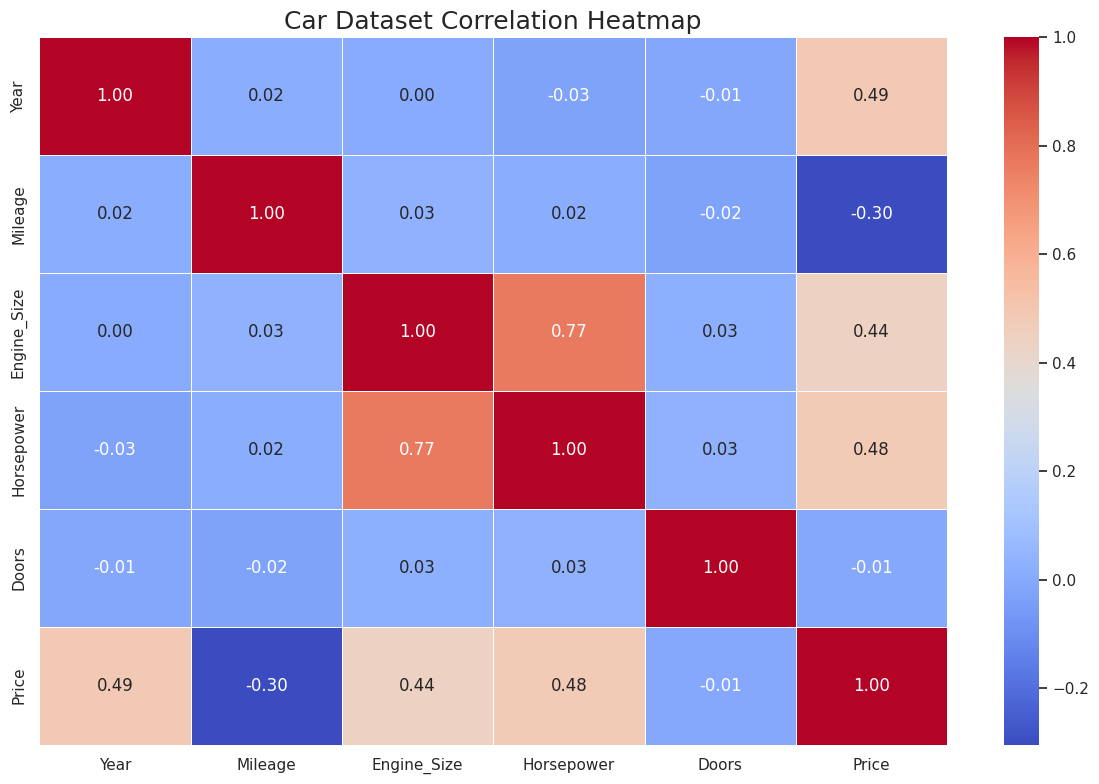

Correlation with car price:


,Price
Price,1.000000
Year,0.488530
Horsepower,0.477475
Engine_Size,0.435362
Doors,-0.006666
Mileage,-0.303917


In [12]:

# Numerical correlation analysis

numeric_df = df.select_dtypes(
    include=np.number
)

correlation = numeric_df.corr()

plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    linewidths=0.5
)

plt.title(
    "Car Dataset Correlation Heatmap",
    fontsize=18
)

plt.tight_layout()
plt.show()

print("Correlation with car price:")

display(
    correlation["Price"]
    .sort_values(ascending=False)
)


In [13]:

# Create machine learning features

ml_df = df.copy()

# Calculate vehicle age
ml_df["Car_Age"] = 2026 - ml_df["Year"]

# Separate target and features
X = ml_df.drop(
    columns=["Price", "Year"]
)

y = ml_df["Price"]

# Encode categorical features
X = pd.get_dummies(
    X,
    columns=[
        "Brand",
        "Fuel_Type",
        "Transmission"
    ],
    dtype=int
)

print("Features prepared successfully!")

print("\nFeature shape:", X.shape)
print("Target shape:", y.shape)

display(X.head())


Features prepared successfully!

Feature shape: (2500, 19)
Target shape: (2500,)


,Mileage,Engine_Size,Horsepower,Doors,Car_Age,Brand_Audi,Brand_BMW,Brand_Honda,Brand_Hyundai,Brand_Kia,Brand_Maruti,Brand_Mercedes,Brand_Toyota,Fuel_Type_Diesel,Fuel_Type_Electric,Fuel_Type_Hybrid,Fuel_Type_Petrol,Transmission_Automatic,Transmission_Manual
0,70504,4.5,150,5,3,1,0,0,0,0,0,0,0,0,0,0,1,1,0
1,100214,2.6,114,2,2,0,0,0,0,0,0,1,0,0,0,1,0,0,1
2,114936,2.7,121,4,3,0,0,0,1,0,0,0,0,1,0,0,0,1,0
3,17279,2.1,74,4,10,1,0,0,0,0,0,0,0,0,0,1,0,0,1
4,104751,3.8,245,4,0,0,1,0,0,0,0,0,0,0,0,1,0,1,0


In [14]:

# Split dataset into training and testing

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Training records:", len(X_train))
print("Testing records:", len(X_test))

# Create Random Forest model
model = RandomForestRegressor(
    n_estimators=150,
    max_depth=15,
    min_samples_leaf=2,
    random_state=42,
    n_jobs=-1
)

# Train model
model.fit(
    X_train,
    y_train
)

print("\nModel training completed!")


Training records: 2000
Testing records: 500

Model training completed!


In [15]:

# Generate predictions

y_pred = model.predict(X_test)

# Calculate evaluation metrics

mae = mean_absolute_error(
    y_test,
    y_pred
)

mse = mean_squared_error(
    y_test,
    y_pred
)

rmse = np.sqrt(mse)

r2 = r2_score(
    y_test,
    y_pred
)

# Display results

print("=" * 50)
print("         MODEL PERFORMANCE")
print("=" * 50)

print(f"Mean Absolute Error: ₹{mae:,.2f}")

print(f"Mean Squared Error: {mse:,.2f}")

print(f"Root Mean Squared Error: ₹{rmse:,.2f}")

print(f"R² Score: {r2:.4f}")

print("=" * 50)


         MODEL PERFORMANCE
Mean Absolute Error: ₹197,651.58
Mean Squared Error: 81,753,262,226.64
Root Mean Squared Error: ₹285,925.27
R² Score: 0.8667


In [16]:

# Compare actual and predicted prices

comparison = pd.DataFrame({
    "Actual Price": y_test.values,
    "Predicted Price": y_pred
})

fig = px.scatter(
    comparison,
    x="Actual Price",
    y="Predicted Price",
    title="Actual vs. Predicted Car Prices",
    labels={
        "Actual Price": "Actual Price (INR)",
        "Predicted Price": "Predicted Price (INR)"
    }
)

# Add ideal prediction line
minimum = min(
    comparison["Actual Price"].min(),
    comparison["Predicted Price"].min()
)

maximum = max(
    comparison["Actual Price"].max(),
    comparison["Predicted Price"].max()
)

fig.add_trace(
    go.Scatter(
        x=[minimum, maximum],
        y=[minimum, maximum],
        mode="lines",
        name="Ideal Prediction"
    )
)

fig.update_layout(
    template="plotly_white",
    height=600
)

fig.show()


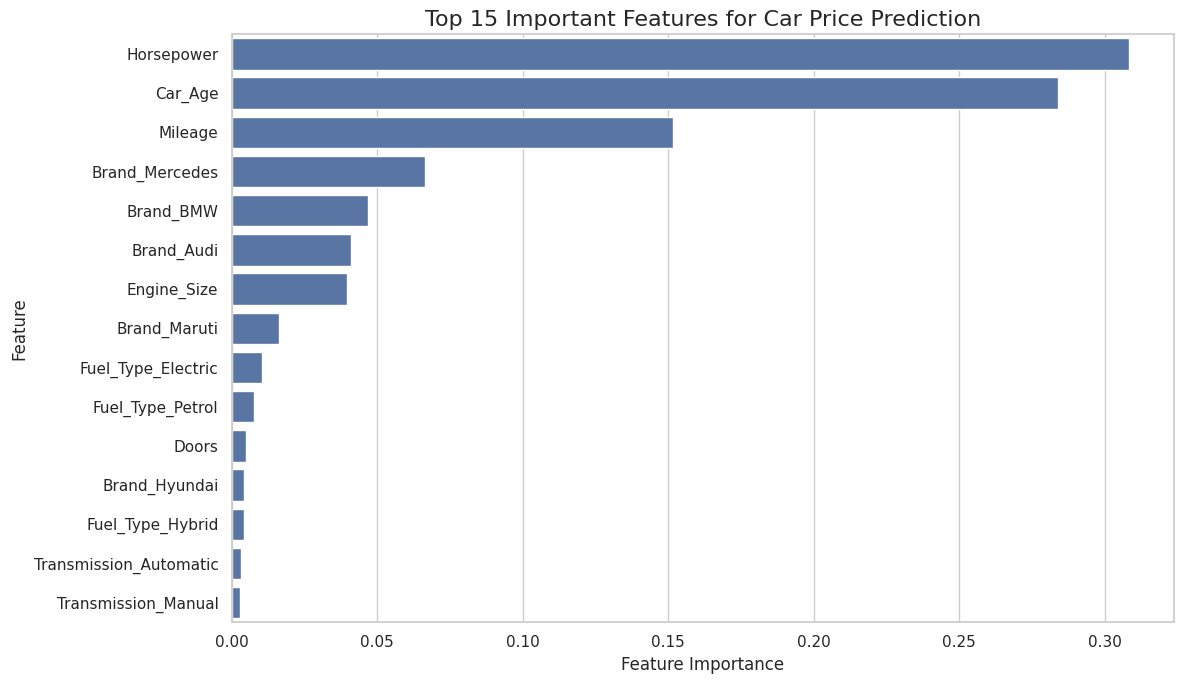

,Feature,Importance
2,Horsepower,0.308443
4,Car_Age,0.284057
0,Mileage,0.151661
11,Brand_Mercedes,0.066563
6,Brand_BMW,0.046992
5,Brand_Audi,0.041012
1,Engine_Size,0.039740
10,Brand_Maruti,0.016371
14,Fuel_Type_Electric,0.010460
16,Fuel_Type_Petrol,0.007654


In [17]:

# Identify the most important features

importance = pd.DataFrame({
    "Feature": X.columns,
    "Importance": model.feature_importances_
})

importance = importance.sort_values(
    by="Importance",
    ascending=False
)

top_features = importance.head(15)

plt.figure(figsize=(12, 7))

sns.barplot(
    data=top_features,
    x="Importance",
    y="Feature"
)

plt.title(
    "Top 15 Important Features for Car Price Prediction",
    fontsize=16
)

plt.xlabel("Feature Importance")
plt.ylabel("Feature")

plt.tight_layout()
plt.show()

display(top_features)


In [18]:

# Interactive prediction function

def predict_car_price(
    brand,
    year,
    mileage,
    engine_size,
    horsepower,
    fuel_type,
    transmission,
    doors
):

    # Create input data
    car = pd.DataFrame([{
        "Brand": brand,
        "Mileage": mileage,
        "Engine_Size": engine_size,
        "Horsepower": horsepower,
        "Fuel_Type": fuel_type,
        "Transmission": transmission,
        "Doors": doors,
        "Car_Age": 2026 - year
    }])

    # Encode categorical variables
    car = pd.get_dummies(
        car,
        columns=[
            "Brand",
            "Fuel_Type",
            "Transmission"
        ],
        dtype=int
    )

    # Match model training features
    car = car.reindex(
        columns=X.columns,
        fill_value=0
    )

    # Predict price
    prediction = model.predict(car)[0]

    return prediction


# Example car

predicted_price = predict_car_price(
    brand="Toyota",
    year=2023,
    mileage=25000,
    engine_size=2.0,
    horsepower=150,
    fuel_type="Petrol",
    transmission="Automatic",
    doors=4
)

print("=" * 45)
print("       CAR PRICE PREDICTION")
print("=" * 45)

print(f"Predicted Price: ₹{predicted_price:,.2f}")

print("=" * 45)


       CAR PRICE PREDICTION
Predicted Price: ₹1,816,858.93


In [19]:

# User input interface for Google Colab

from ipywidgets import (
    interact,
    IntSlider,
    FloatSlider,
    Dropdown
)

def interactive_car_prediction(
    brand,
    year,
    mileage,
    engine_size,
    horsepower,
    fuel_type,
    transmission,
    doors
):

    predicted = predict_car_price(
        brand,
        year,
        mileage,
        engine_size,
        horsepower,
        fuel_type,
        transmission,
        doors
    )

    print("\n" + "=" * 45)
    print("       PREDICTED CAR PRICE")
    print("=" * 45)

    print(f"Brand: {brand}")
    print(f"Year: {year}")
    print(f"Mileage: {mileage:,} km")
    print(f"Engine: {engine_size} L")
    print(f"Horsepower: {horsepower}")
    print(f"Fuel: {fuel_type}")
    print(f"Transmission: {transmission}")

    print("-" * 45)

    print(f"Predicted Price: ₹{predicted:,.2f}")

    print("=" * 45)


interact(
    interactive_car_prediction,

    brand=Dropdown(
        options=brands,
        value="Toyota",
        description="Brand:"
    ),

    year=IntSlider(
        min=2010,
        max=2026,
        value=2023,
        description="Year:"
    ),

    mileage=IntSlider(
        min=0,
        max=180000,
        step=1000,
        value=25000,
        description="Mileage:"
    ),

    engine_size=FloatSlider(
        min=0.8,
        max=5.0,
        step=0.1,
        value=2.0,
        description="Engine:"
    ),

    horsepower=IntSlider(
        min=40,
        max=350,
        value=150,
        description="HP:"
    ),

    fuel_type=Dropdown(
        options=fuel_types,
        value="Petrol",
        description="Fuel:"
    ),

    transmission=Dropdown(
        options=transmissions,
        value="Automatic",
        description="Transmission:"
    ),

    doors=Dropdown(
        options=[2, 4, 5],
        value=4,
        description="Doors:"
    )
)


interactive(children=(Dropdown(description='Brand:', options=('Toyota', 'Honda', 'BMW', 'Mercedes', 'Hyundai',…

<function __main__.interactive_car_prediction(brand, year, mileage, engine_size, horsepower, fuel_type, transmission, doors)>

In [20]:

# Export test predictions

results = pd.DataFrame({
    "Actual_Price": y_test.values,
    "Predicted_Price": y_pred
})

results["Difference"] = (
    results["Actual_Price"]
    - results["Predicted_Price"]
)

results["Absolute_Error"] = (
    results["Difference"].abs()
)

results.to_csv(
    "car_price_predictions.csv",
    index=False
)

print("Prediction results exported!")

from google.colab import files

files.download(
    "car_price_predictions.csv"
)


Prediction results exported!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

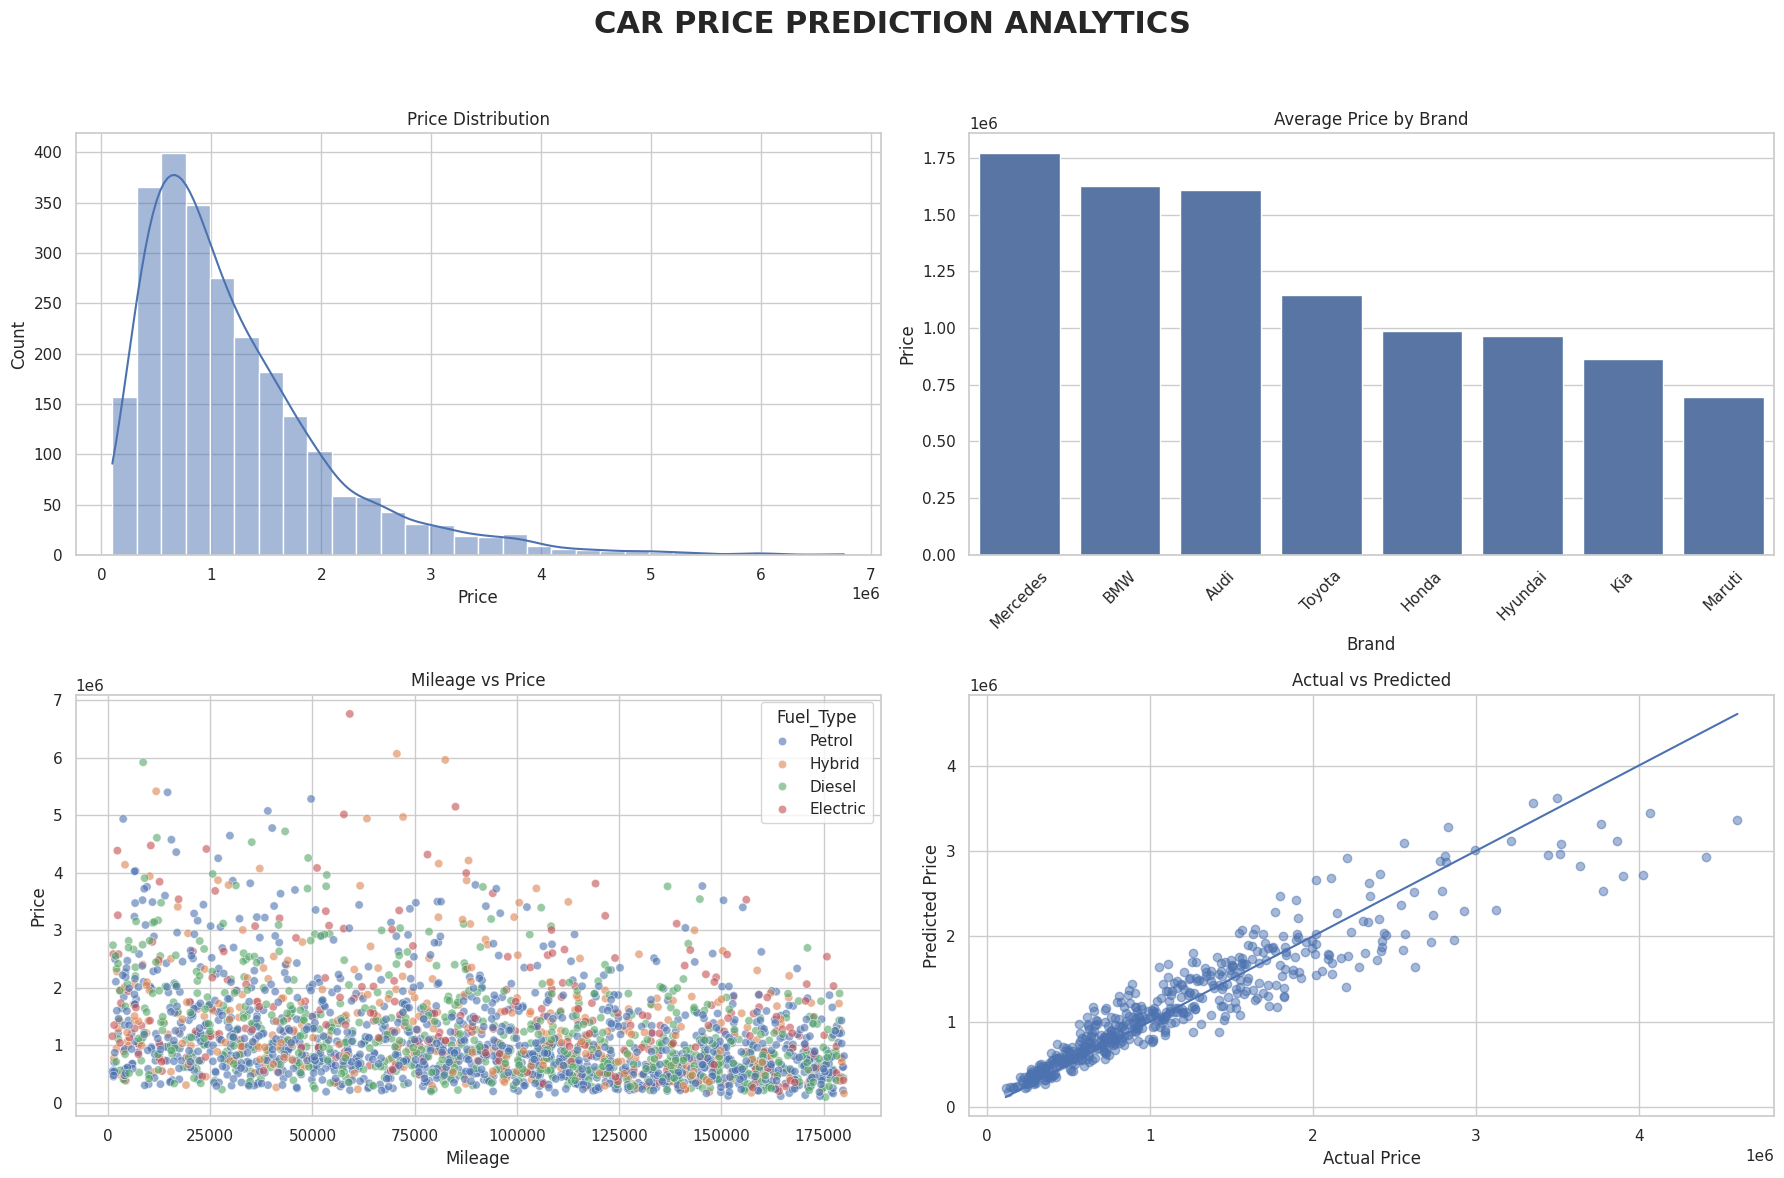

In [21]:

# Complete Car Analytics Dashboard

fig = plt.figure(
    figsize=(18, 12)
)

fig.suptitle(
    "CAR PRICE PREDICTION ANALYTICS",
    fontsize=22,
    fontweight="bold"
)

# 1. Price distribution
ax1 = plt.subplot(2, 2, 1)

sns.histplot(
    df["Price"],
    bins=30,
    kde=True,
    ax=ax1
)

ax1.set_title("Price Distribution")

# 2. Brand price
ax2 = plt.subplot(2, 2, 2)

sns.barplot(
    data=brand_prices,
    x="Brand",
    y="Price",
    ax=ax2
)

ax2.set_title("Average Price by Brand")

ax2.tick_params(
    axis="x",
    rotation=45
)

# 3. Mileage and price
ax3 = plt.subplot(2, 2, 3)

sns.scatterplot(
    data=df,
    x="Mileage",
    y="Price",
    hue="Fuel_Type",
    alpha=0.6,
    ax=ax3
)

ax3.set_title("Mileage vs Price")

# 4. Actual vs predicted
ax4 = plt.subplot(2, 2, 4)

ax4.scatter(
    y_test,
    y_pred,
    alpha=0.5
)

ax4.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()]
)

ax4.set_title("Actual vs Predicted")

ax4.set_xlabel("Actual Price")

ax4.set_ylabel("Predicted Price")

plt.tight_layout(
    rect=[0, 0, 1, 0.95]
)

plt.show()
